Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 861, 16)        │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 430, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 430, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 429, 32)        │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 214, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 214, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 213, 64)        │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 106, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 106, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 105, 128)       │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 52, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 52, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,776 (85.06 KB)

 Trainable params: 21,776 (85.06 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
[0]	validation_0-mlogloss:0.59840
[1]	validation_0-mlogloss:0.59156
[2]	validation_0-mlogloss:0.58519
[3]	validation_0-mlogloss:0.57943
[4]	validation_0-mlogloss:0.57311
[5]	validation_0-mlogloss:0.56755
[6]	validation_0-mlogloss:0.56480
[7]	validation_0-mlogloss:0.55866
[8]	validation_0-mlogloss:0.55654
[9]	validation_0-mlogloss:0.55464


E:\anaconda3\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:12:09] WARNING: D:\bld\xgboost-split_1772124964810\work\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()


[10]	validation_0-mlogloss:0.55202
[11]	validation_0-mlogloss:0.55026
[12]	validation_0-mlogloss:0.54877
[13]	validation_0-mlogloss:0.54729
[14]	validation_0-mlogloss:0.54689
[15]	validation_0-mlogloss:0.54568
[16]	validation_0-mlogloss:0.54485
[17]	validation_0-mlogloss:0.54317
[18]	validation_0-mlogloss:0.54162
[19]	validation_0-mlogloss:0.53992
[20]	validation_0-mlogloss:0.53842
[21]	validation_0-mlogloss:0.53752
[22]	validation_0-mlogloss:0.53712
[23]	validation_0-mlogloss:0.53689
[24]	validation_0-mlogloss:0.53728
[25]	validation_0-mlogloss:0.53706
[26]	validation_0-mlogloss:0.53670
[27]	validation_0-mlogloss:0.53604
[28]	validation_0-mlogloss:0.53711
[29]	validation_0-mlogloss:0.53742
[30]	validation_0-mlogloss:0.53791
[31]	validation_0-mlogloss:0.53850
[32]	validation_0-mlogloss:0.53868
[33]	validation_0-mlogloss:0.53841
[34]	validation_0-mlogloss:0.53752
[35]	validation_0-mlogloss:0.53833
[36]	validation_0-mlogloss:0.53816
[37]	validation_0-mlogloss:0.53951
XGBoost Test Accurac

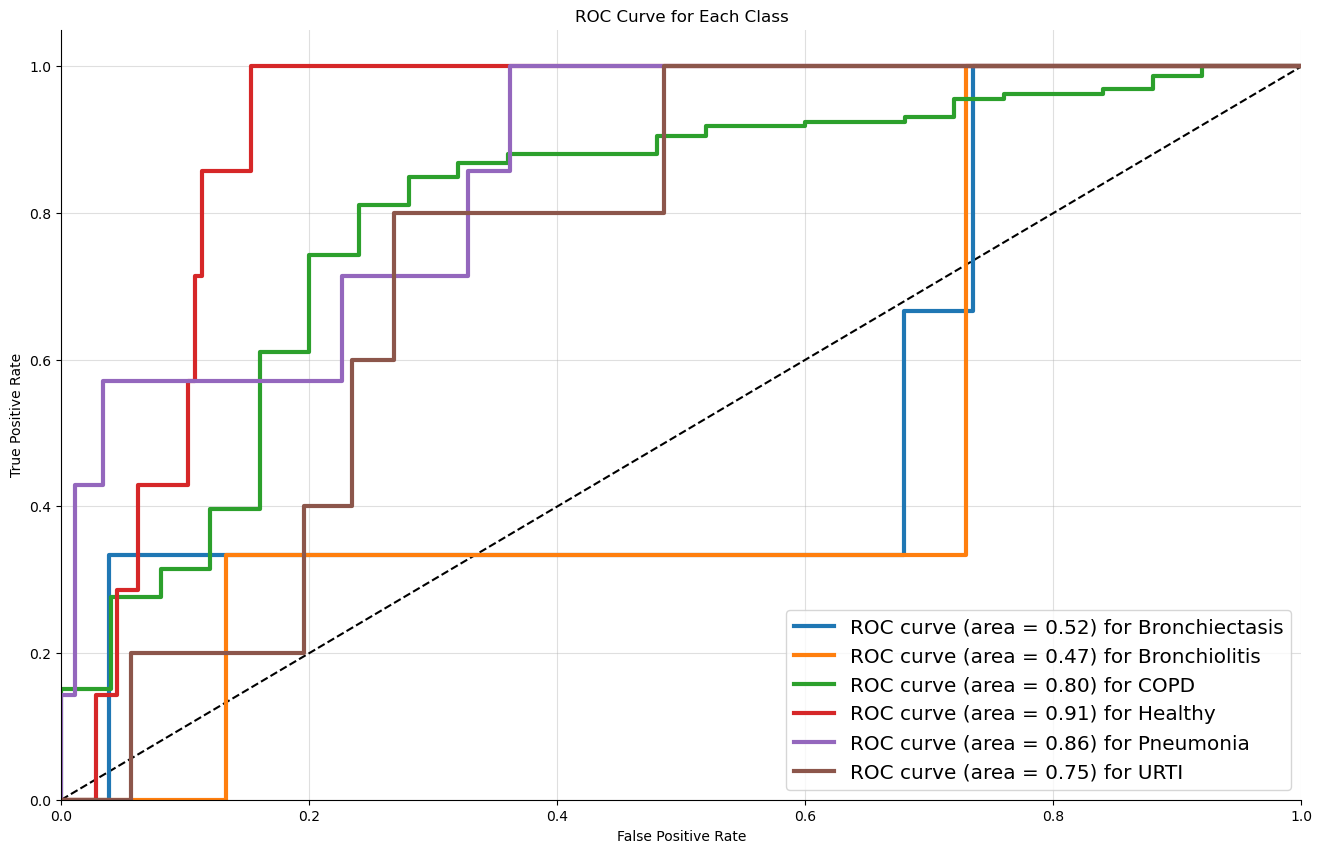

In [1]:
"""
================================================================================
Experiment Spectrogram: Spectrogram + CNN + XGBoost
================================================================================
This script is part of the 75 exploratory experiments. It performs:
- Feature extraction: Spectrogram (STFT magnitude, dB) averaged over time.
- Method: CNN (1D) features + XGBoost classifier (no imbalance handling).
- No patient-level splitting (80/20 recording-level split) – exploratory only.
- Calculates accuracy, classification report, confusion matrix, ROC curves.

Author: Ehab Hassan Abdel Hady
Date: 2025
Based on original code from the paper.
"""

import warnings
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
from datetime import datetime
from os import listdir
from os.path import isfile, join, basename
import librosa
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, GlobalAveragePooling1D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress librosa warnings
warnings.filterwarnings("ignore", category=UserWarning, module="librosa")

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function (Spectrogram only)
def extract_features(file_name):
    try:
        # Load audio file with a fixed duration (20 seconds)
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        
        # Extract Spectrogram (Short-Time Fourier Transform)
        stft = librosa.stft(audio)
        spectrogram = np.abs(stft)  # Magnitude of the STFT
        spectrogram_db = librosa.amplitude_to_db(spectrogram, ref=np.max)  # Convert to dB
        spectrogram_mean = np.mean(spectrogram_db, axis=1)  # Average over time
        
        # Use only spectrogram features
        features = spectrogram_mean
        
        # Pad features to ensure consistent length
        if features.shape[0] < max_pad_len:
            pad_width = max_pad_len - features.shape[0]
            features = np.pad(features, pad_width=(0, pad_width), mode='constant')
        elif features.shape[0] > max_pad_len:
            features = features[:max_pad_len]  # Truncate if longer than max_pad_len
        
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return features

# Extract features for all files
filepaths = [join(mypath, f) for f in filenames]
features = []
valid_files = []
for file_name in filepaths:
    feature = extract_features(file_name)
    if feature is not None:
        features.append(feature)
        valid_files.append(file_name)

# Convert features to numpy array
features = np.array(features)

# Load labels for valid files
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv", header=None)

# Extract the first three characters from the file name (not the full path)
labels = np.array([p_diag[p_diag[0] == int(basename(name)[:3])][1].values[0] for name in valid_files])

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN (1D input)
features1 = np.reshape(features1, (*features1.shape, 1))  # Shape: (num_samples, max_pad_len, 1)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction (1D CNN)
num_columns = max_pad_len
num_channels = 1
filter_size = 2

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_columns, num_channels)))  # Input shape: (max_pad_len, 1)
cnn_model.add(Conv1D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv1D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv1D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv1D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling1D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for XGBoost
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for XGBoost
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# XGBoost model with adjusted hyperparameters (no class weights, no SMOTE)
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    early_stopping_rounds=10
)

# Train the XGBoost model (no sample weights)
xgb_model.fit(
    x_train_features, y_train,
    eval_set=[(x_test_features, y_test)],
    verbose=True
)

# Evaluate model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Evaluating the model on the training set
y_train_pred = xgb_model.predict(x_train_features)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"XGBoost Training Accuracy: {train_accuracy:.4f}")

# Evaluating the model on the testing set
y_test_pred = xgb_model.predict(x_test_features)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"XGBoost Testing Accuracy: {test_accuracy:.4f}")

# Confusion matrix and classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()